In [1]:
from asyncio.tools import display_awaited_by_tasks_table
from itertools import groupby

import kagglehub

# Download latest version
path = kagglehub.dataset_download("rodsaldanha/arketing-campaign")

print("Path to dataset files:", path)

C:\Users\Maxim\PycharmProjects\XGBoost_Marketing_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Maxim\.cache\kagglehub\datasets\rodsaldanha\arketing-campaign\versions\8


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


data_dir = Path(path)
csv_files = list(data_dir.glob("*.csv"))
print("CSV files:", csv_files)

assert len(csv_files) == 1

df = pd.read_csv(csv_files[0], sep=";")

df.info()

display(df.head())
display(df.sample(5, random_state=42))
display(df.tail())

CSV files: [WindowsPath('C:/Users/Maxim/.cache/kagglehub/datasets/rodsaldanha/arketing-campaign/versions/8/marketing_campaign.csv')]
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
324,2607,1953,Graduation,Single,40464.0,0,1,2013-01-11,78,424,...,8,0,0,0,0,0,0,3,11,0
96,7247,1960,Graduation,Widow,47916.0,0,1,2012-11-22,72,505,...,6,0,1,0,0,0,0,3,11,0
2104,5802,1972,Basic,Married,14188.0,0,0,2013-02-28,40,2,...,6,0,0,0,0,0,0,3,11,0
1259,2147,1969,Graduation,Together,76653.0,0,0,2013-08-16,91,736,...,2,0,0,1,1,0,0,3,11,0
1061,3759,1958,Graduation,Together,65196.0,0,2,2013-07-25,34,743,...,5,1,0,0,0,0,0,3,11,0


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,3,0,0,0,0,0,0,3,11,0
2239,9405,1954,PhD,Married,52869.0,1,1,2012-10-15,40,84,...,7,0,0,0,0,0,0,3,11,1


In [3]:
# Пропущенные значения
print(f"\nMissing values\n{df.isna().sum().sort_values(ascending=False).head(10)}")

# Получаем сумму дубликатов
print(f"\nDuplicated rows: {df.duplicated().sum()}")

# Распределение переменной
print("\nTarget distribution")
print(df["Response"].value_counts(normalize=True))

# Получаем константные признаки
constant_cols = df.columns[
    df.nunique(dropna = False) <= 1
].tolist()
print(f"\n Constant_cols: {constant_cols}")

if "ID" in df.columns:
    print(f"Duplicated IDs: {df["ID"].duplicated().sum()}")

valid_years = df["Year_Birth"].dropna()
valid_mask = (df["Year_Birth"] >= 1900) & (df["Year_Birth"] < 2026)
mean_years = (2026 - valid_years[valid_mask]).mean()

print(f"{mean_years: .2f}")



Missing values
Income            24
ID                 0
Year_Birth         0
Education          0
Marital_Status     0
Kidhome            0
Teenhome           0
Dt_Customer        0
Recency            0
MntWines           0
dtype: int64

Duplicated rows: 0

Target distribution
Response
0    0.850893
1    0.149107
Name: proportion, dtype: float64

 Constant_cols: ['Z_CostContact', 'Z_Revenue']
Duplicated IDs: 0
 57.13


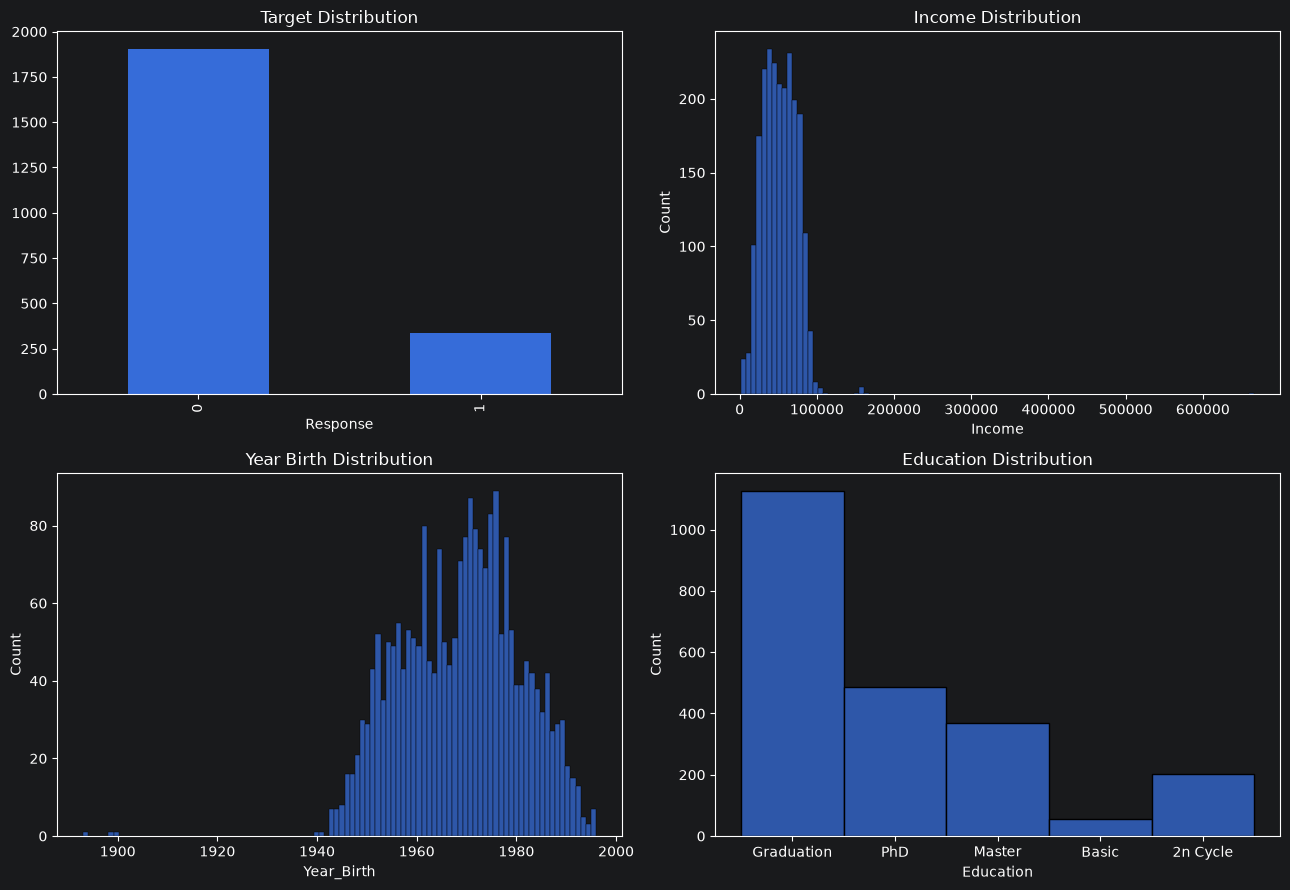

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))

# Балланс целевой переменной
df["Response"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Target Distribution")
axes[0, 0].set_xlabel("Response")

# Распределение дохода
sns.histplot(
    data=df,x="Income", bins=100,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Income Distribution")

sns.histplot(
    data=df, x="Year_Birth", bins=100,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Year Birth Distribution")

sns.histplot(
    data=df, x="Education", bins=100,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Education Distribution")

plt.tight_layout()
plt.show()


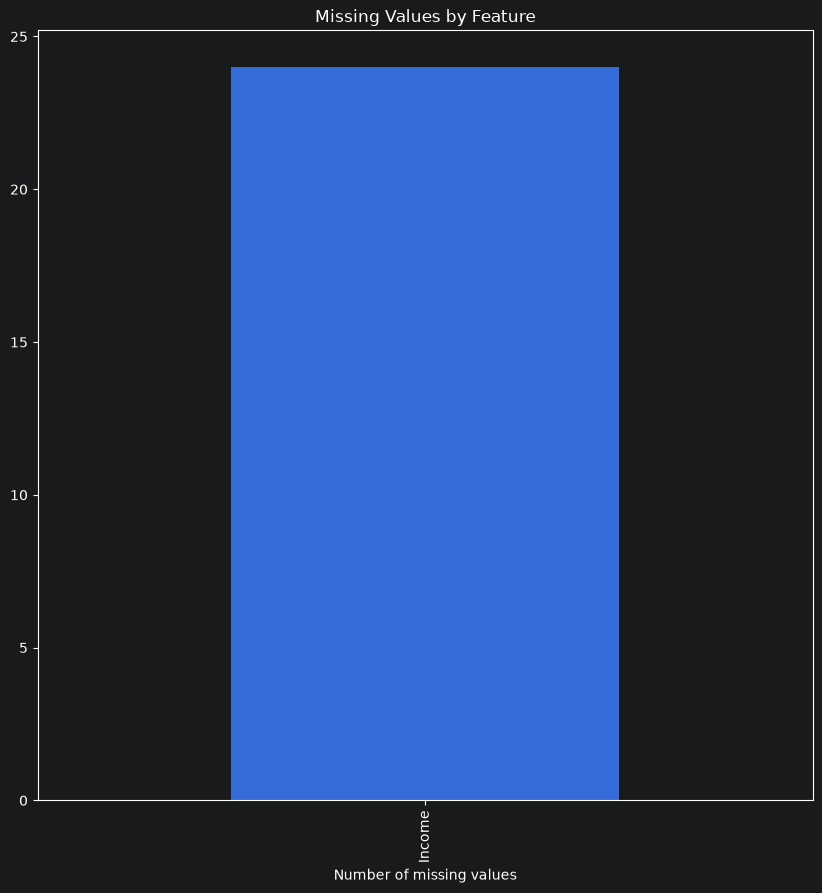

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

if not missing.empty:
    plt.figure(figsize=(10,10))
    missing.plot(kind="bar")
    plt.title("Missing Values by Feature")
    plt.xlabel("Number of missing values")
    plt.show()
else:
    print("Пропусков не обнаружено")


# ***Исследование данных***

**Эксперимент А**
Исследуем подозрительные даты рождения.

Анализ показал аномальные выбросы в данных по возрасту: некоторые значения уходят за пределы порога 1900 года.

**Эксперимент B**
Исследуем экстремальные доходы

**Эксперимент С**
Смотрим на доход без влияния самых больших значений

In [6]:
# Основная статистика
print(df["Year_Birth"].describe())

# Сколько клиентов родилось до 1926 года (возраст 100 лет).
# Исходим из предположения, что рекламная компания завершилась в 2026 году.
old_clients = df.loc[df["Year_Birth"] < 1926]
print("fNumber of old: ", len(old_clients))

clients_profile = ["ID", "Year_Birth", "Income", "Education", "Marital_Status"]

display(
    old_clients[clients_profile].drop_duplicates().sort_values("Year_Birth")
)


count    2240.000000
mean     1968.805804
std        11.984069
min      1893.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64
fNumber of old:  3


,ID,Year_Birth,Income,Education,Marital_Status
239,11004,1893,60182.0,2n Cycle,Single
339,1150,1899,83532.0,PhD,Together
192,7829,1900,36640.0,2n Cycle,Divorced


In [7]:
print(
    df["Income"].describe(
        percentiles=[0.01, 0.05, 0.25,
            0.50, 0.75, 0.95, 0.99]
    )
)

display(
    df.nlargest(10, "Income")[clients_profile]
)

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
1%         7579.200000
5%        18985.500000
25%       35303.000000
50%       51381.500000
75%       68522.000000
95%       84130.000000
99%       94458.800000
max      666666.000000
Name: Income, dtype: float64


,ID,Year_Birth,Income,Education,Marital_Status
2233,9432,1977,666666.0,Graduation,Together
617,1503,1976,162397.0,PhD,Together
687,1501,1982,160803.0,PhD,Married
1300,5336,1971,157733.0,Master,Together
164,8475,1973,157243.0,PhD,Married
1653,4931,1977,157146.0,Graduation,Together
2132,11181,1949,156924.0,PhD,Married
655,5555,1975,153924.0,Graduation,Divorced
1898,4619,1945,113734.0,PhD,Single
646,4611,1970,105471.0,Graduation,Together


Проверяем насколько сильно оказывают влияние на распределение экстремальные выбросы. Строим графики для визуальной инспекции

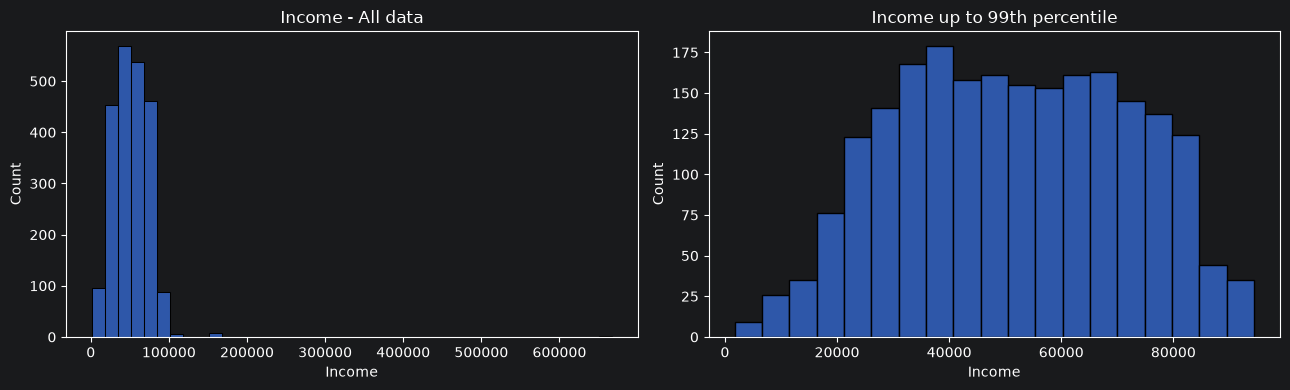

In [8]:
income_99 = df["Income"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize = (13, 4))

sns.histplot(
    data = df, x="Income", bins=40,
    ax = axes[0]
)
axes[0].set_title("Income - All data")

sns.histplot(
    data = df[df["Income"] <= income_99], x="Income",
    ax = axes[1]
)
axes[1].set_title("Income up to 99th percentile")
sns.histplot()

plt.tight_layout()
plt.show()

Найден доход со значением 666 666. Принято решение не исключать значение из датасета. Для нивелирования негативного эффекта выброса логорифмировать показатель для работы с линейными моделями. При работе с Random Forest экстремальные выбросы оказывают менее негативное влияние на общую результативность модели, поэтому предлагается сравнить результаты моделей

Очистка данных. Убираем всех клиентов с возрастом более 100 лет, принимая это за ошибку данных.

In [9]:
campaign_year = 2026

df_clean = df.copy()
df_clean["Age"] = campaign_year - df_clean["Year_Birth"]

old_clients_exclude = df_clean[df_clean['Age'] > 100]
print("fNumber of old clients: ", len(old_clients_exclude))

df_clean = df_clean[df_clean["Age"] <= 100]

print("old data: ", df.shape)
print("new data: ", df_clean.shape)

fNumber of old clients:  3
old data:  (2240, 29)
new data:  (2237, 30)


Разделяем датасет на обучающую (60%), валидационную (20%) и тестовую (20%) выборки. Рассчитываем медиану Income на обучающей выборке и используем её для заполнения пропусков во всех трёх. Расчитываем медиану только на обучающей выборке, чтобы сохранить клиентов с неизвестным доходом и избежать утечки информации из валидационной и тестовой выборок.

In [10]:
from sklearn.model_selection import train_test_split, cross_val_score

# 1. Разделяем данные, сохраняя пропорции классов Response. 60% - train, 20% - validate, 20% - test
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.4,
    stratify=df_clean["Response"],
    random_state=42,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["Response"],
    random_state=42,
)

# Создаем независимые копии данных
train_df = train_df.copy()
test_df = test_df.copy()
val_df = val_df.copy()

# Вычисляем медиану Income только на обучающих данных, для предотвращения утечки данных
income_median = train_df["Income"].median()

# 4. Заполняем пропуски одинаковой медианой
dataset = [train_df, val_df, test_df]
for ds in dataset:
    ds["Income"] = ds["Income"].fillna(income_median)

for name, dataset in [
    ("Train", train_df),
    ("Validate", val_df),
    ("Test", test_df),
]:
    print(f"{name}, {dataset.shape} Missing Income: {dataset["Income"].isna().sum()}")


Train, (1342, 30) Missing Income: 0
Validate, (447, 30) Missing Income: 0
Test, (448, 30) Missing Income: 0


Этап Feature Engineering. Отбираем признаки для модели. Изучаем структуру всех признаков, строим корреляционную матрицу и смотрим на зависимости.

,Data type,Unique values,Missing values
ID,int64,1342,0
Year_Birth,int64,56,0
Education,str,5,0
Marital_Status,str,8,0
Income,float64,1240,0
Kidhome,int64,3,0
Teenhome,int64,3,0
Dt_Customer,str,585,0
Recency,int64,100,0
MntWines,int64,581,0


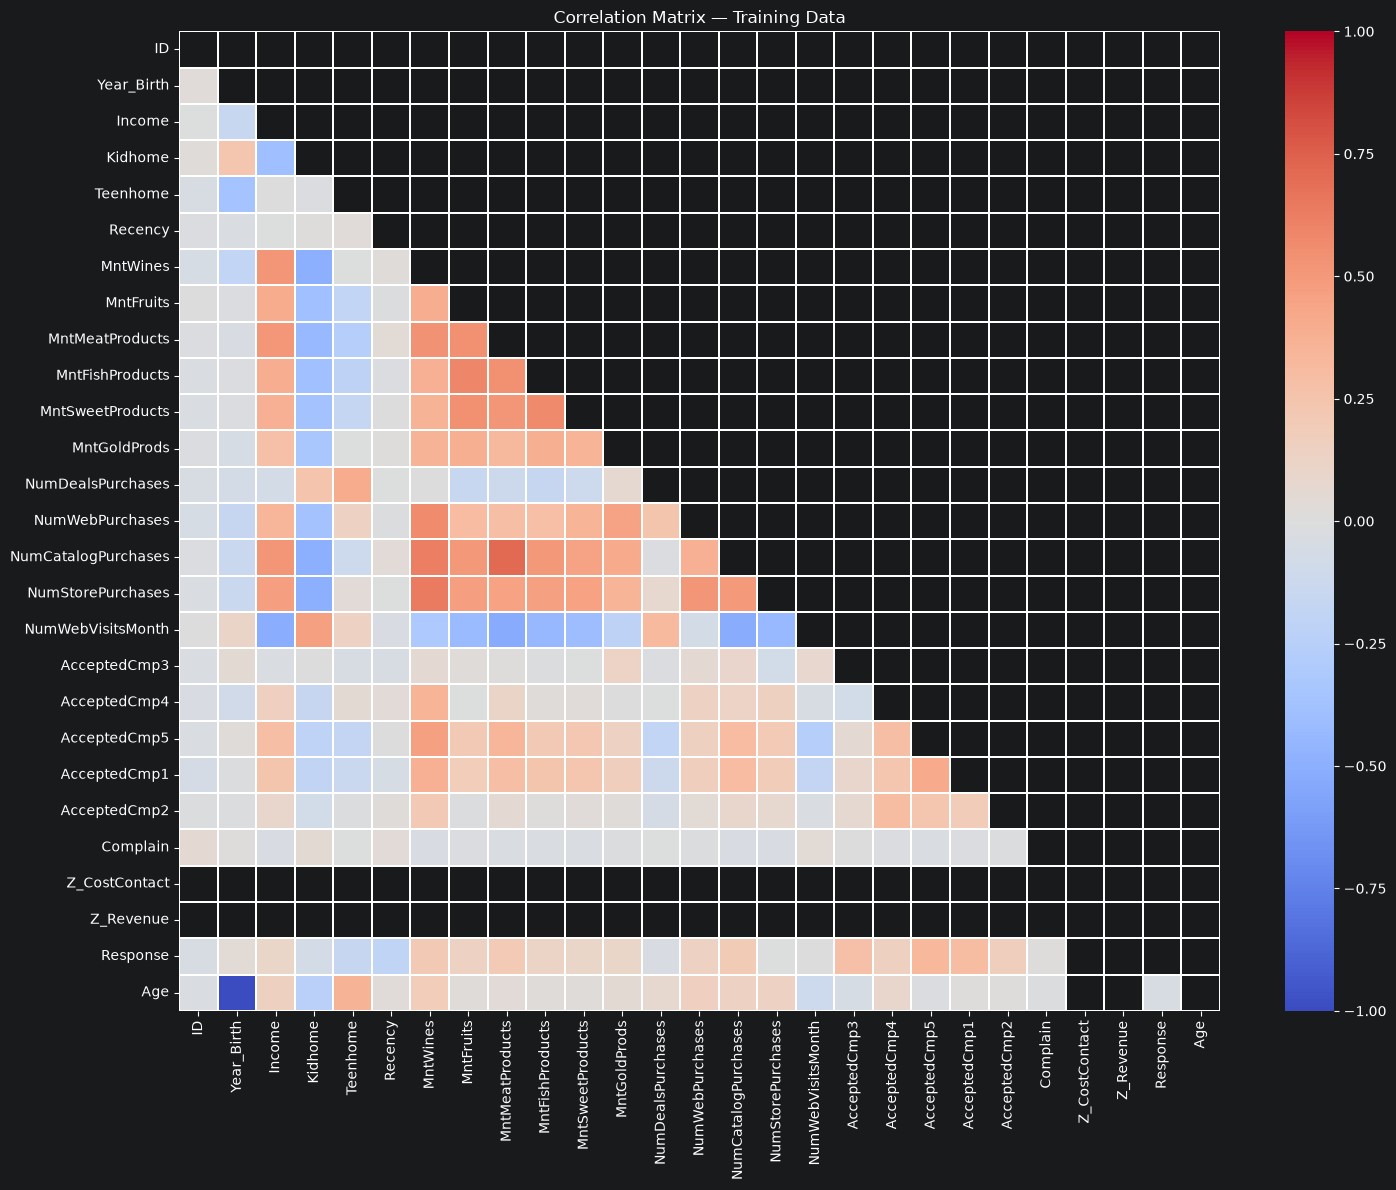

In [11]:
# 1. Изучаем структуру всех признаков
feature_info = pd.DataFrame({
    "Data type": train_df.dtypes,
    "Unique values": train_df.nunique(dropna=False),
    "Missing values":train_df.isna().sum()
})

display(feature_info)

# 2. Выбираем числовые признаки для корреляционного анализа
numeric_data = train_df.select_dtypes(include="number")

# 3. Формируем корреляционную матрицу Пирсона
corr_matrix = numeric_data.corr()

# 4. Визуализируем связи между числовыми признаками
plt.figure(figsize=(15, 12))

mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool)
)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Correlation Matrix — Training Data")
plt.tight_layout()
plt.show()

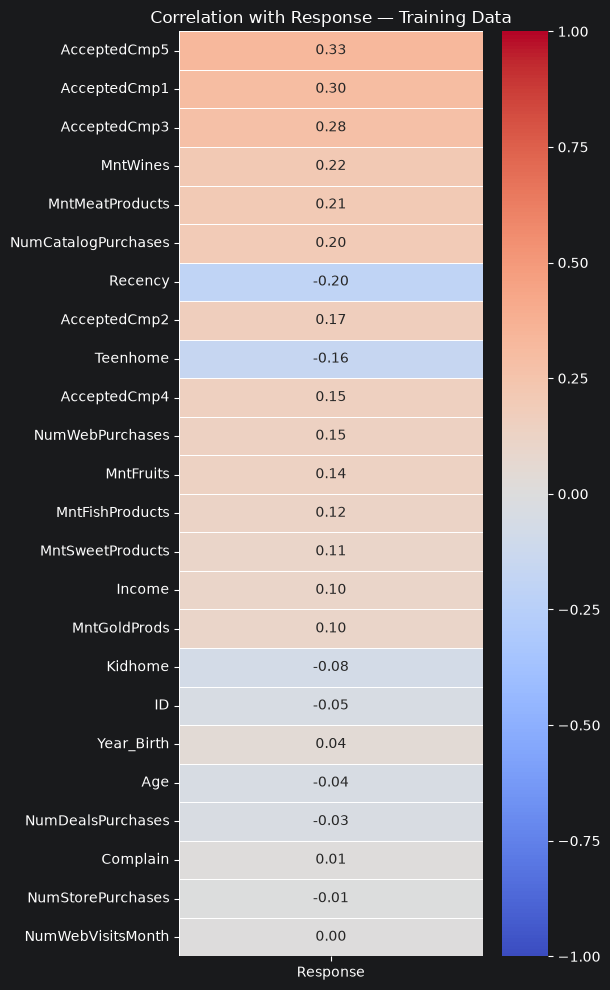

In [12]:
# 1. Рассчитываем корреляции только на обучающей выборке
corr_matrix = train_df.select_dtypes(include="number").corr()

# 2. Берём корреляции всех признаков с Response
target_corr = (
    corr_matrix["Response"]
    .drop("Response")
    .dropna()
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

# 3. Показываем численные значения на тепловой карте
plt.figure(figsize=(6, 10))

sns.heatmap(
    target_corr.to_frame(name="Response"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation with Response — Training Data")
plt.tight_layout()
plt.show()

По результатам корреляционного анализа мы не можем сделать вывод о наличии выраженной мультиколлинеарности или зависимости между признаками и Response. На текущем этапе оставляем набор признаков, как есть за исключением технического столбца ID. Также, по корреляционной матрице видно, что мы не получили значения по колонкам Z_CostContract и Z_Revenue. Далее проведем небольшой тест, чтобы проверить, какую информацию в себе содержат колонки

In [13]:
# Проверяем, являются ли признаки константными
columns = ["Z_CostContact", "Z_Revenue"]

for col in columns:
    print(f"{col}:")
    print("Unique values:", train_df[col].unique())
    print("Number of unique values:", train_df[col].nunique())
    print("Standard deviation:", train_df[col].std())
    print()

Z_CostContact:
Unique values: [3]
Number of unique values: 1
Standard deviation: 0.0

Z_Revenue:
Unique values: [11]
Number of unique values: 1
Standard deviation: 0.0




По результатам теста можем сделать вывод, что значения в колонках содержат одинаковые значения для всех клиентов, что потенциально может препятствовать обучению модели. Таким образом, настоящие колонки будут исключены из обучающей, тестовой и валидационных выборок.

In [14]:
# Создаем переменную, в которую будем включать признаки, которые далее планируем исключить
features_to_exclude = [
    "Z_CostContact", "Z_Revenue"
]

,Clients,Response,Response_Rate
Marital_Status,,,
YOLO,1,1,100.00
Absurd,2,1,50.00
Alone,3,1,33.33
Widow,41,12,29.27
Single,289,65,22.49
Divorced,143,27,18.88
Married,515,59,11.46
Together,348,34,9.77


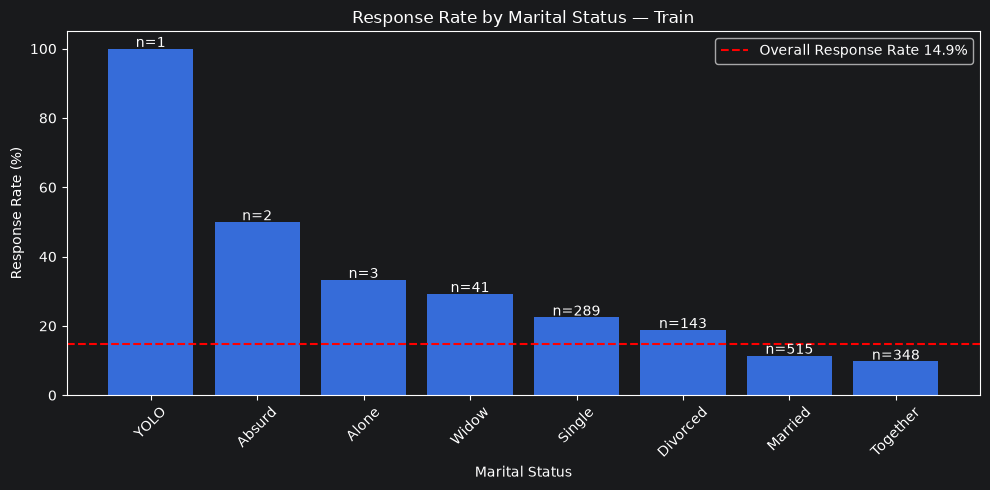

0.643070044709389


In [15]:
# Исследуем данные по семейному положению. Смотрим на состав групп по количеству клиентов и откликов на рекламные компании,
# а также отношение количества откликов к числу клиентов
marital_stats = (
    train_df
    .groupby(["Marital_Status"])["Response"]
    .agg(
        Clients = "count",
        Response = "sum",
        Response_Rate = "mean"
    )
    .sort_values("Response_Rate", ascending=False)
)
marital_stats["Response_Rate"] *= 100
display(marital_stats.round(2))

# Считаем среднюю долю по всей категории
overall_rate = train_df["Response"].mean() * 100

# Визуализируем долю откликов по категориям
fig, axes = plt.subplots(figsize = (10,5))
bars = axes.bar(
    marital_stats.index,
    marital_stats["Response_Rate"],
)

# 5. Показываем средний уровень отклика для сравнения
axes.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Response Rate {overall_rate:.1f}%"
)

# Добавляем количество клиентов над каждым столбцом
for bar,n in zip(bars, marital_stats["Clients"]):
    axes.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"n={n}",
        ha="center",
    )

axes.set_title("Response Rate by Marital Status — Train")
axes.set_ylabel("Response Rate (%)")
axes.set_xlabel("Marital Status")
axes.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

couples_share = (
    marital_stats.loc[["Married", "Together"], "Clients"].sum()
    / marital_stats["Clients"].sum()
)
print(couples_share)


Построенный график позволяет заключить, что существующие признаки YOLO и Absurd не поддаются однозначной интерпретации, при этом признаки имеют мало значений, а также существенно искажают картину данных, потому что не позволяют сделать вывод, что люди из подобных категорий однозначно будут более склонны к взаимодействию с рекламой на основе малочисленных показателей. Таким образом принимается решение исключить признаки из выборки.

In [16]:
# Исключаем признаки из train и val данных.
invalid_statuses = ["YOLO", "Absurd"]
train_model = train_df[
    ~train_df["Marital_Status"].isin(invalid_statuses)
].copy()

val_model = val_df[
    ~val_df["Marital_Status"].isin(invalid_statuses)
].copy()

print(f"Train Model: {train_df.shape} -> {train_model.shape}")
print(train_model)
print(f"Val Model: {val_df.shape} -> {val_model.shape}")
print(val_model)

print("\nОставшиеся категории:")
print(train_model["Marital_Status"].value_counts())


Train Model: (1342, 30) -> (1339, 30)
        ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
513   6036        1959      Master       Together  89120.0        0         0   
346   8553        1965  Graduation        Married  44300.0        1         1   
1902  5896        1987      Master        Married  73395.0        0         0   
1789  6173        1979  Graduation       Together  77298.0        0         1   
2152  9481        1976  Graduation        Married  17148.0        1         0   
...    ...         ...         ...            ...      ...      ...       ...   
1922  3138        1956  Graduation         Single  91249.0        0         0   
1691  6349        1987      Master       Divorced  61787.0        0         0   
18    6565        1949      Master        Married  76995.0        0         1   
1514  3865        1977    2n Cycle       Together  20981.0        0         0   
1006  8952        1953      Master        Married  65569.0        0    

Этап подготовки BaseLine. В качестве BaseLine предлагается использовать Ridge

In [17]:
# Формируем функцию подготовки признаков, чтобы не дублировать фрагменты кода. Переводим Dt_Customer в конкретное
# количество дней с момента взаимодействия с рекламной акцией, отделеяем целевую переменную, формируем X и y выборки
def prepare_feature(data):
    data = data.copy()
    data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"])

    data["Customer_Tenure_Days"] = (
        pd.Timestamp("2026-01-01") - data["Dt_Customer"]
    ).dt.days

    y = data["Response"].copy()

    X = data.drop(columns=[
        "Response",
        "Dt_Customer",
        "Z_CostContact",
        "Z_Revenue",
        "ID",
        "Year_Birth"
        ]
    )

    return X, y

X_train, y_train = prepare_feature(train_model)
X_val, y_val = prepare_feature(val_model)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nКатегорияльные признаки:")
print(X_train.select_dtypes(include=["object", "str"]).columns.tolist())
print("\nПропущенные значения в X_train")
print(X_train.isna().sum().sum())

X_train: (1339, 25)
y_train: (1339,)
X_val: (446, 25)
y_val: (446,)

Категорияльные признаки:
['Education', 'Marital_Status']

Пропущенные значения в X_train
0


Обучаем модель Ridge. Используем One Hot Encoding для категориальных признаков и StandartScaler для приведение признаков к сопотавимому масштабу. Используем Pipeline, он гарантирует, что параметры масштабирования и категории для кодирования определяются только на обучающей выборке. К validation применяются уже обученные преобразования.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

categorical_features = [
    "Marital_Status",
    "Education"
]

numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Создаем преобразования
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown= "ignore",
            sparse_output= False,
        ), categorical_features)
    ]
)

# Объединяем преобразования и создаем модель
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RidgeClassifier(alpha=1.0))
    ]
)

# Обучаем модель на train
ridge_pipeline.fit(X_train, y_train)

# Получаем оценки модели на validation
val_scores = ridge_pipeline.decision_function(X_val)

# Рассчитываем метрики
ap = average_precision_score(y_val, val_scores)
roc_auc = roc_auc_score(y_val, val_scores)

print(f"Positive class rate: {y_val.mean():.4f}")
print(f"Average Precision:   {ap:.4f}")
print(f"ROC-AUC:             {roc_auc:.4f}")

Positive class rate: 0.1502
Average Precision:   0.6662
ROC-AUC:             0.8832


***Результаты baseline-модели RidgeClassifier***

На валидационной выборке доля клиентов, положительно ответивших на маркетинговую кампанию, составила 15,02%, что свидетельствует о дисбалансе классов.

Модель RidgeClassifier показала следующие результаты:

Average Precision = 0,6662

ROC-AUC = 0,8832

Значение Average Precision значительно превышает базовый ориентир случайного ранжирования (~0,15), что указывает на способность модели выделять клиентов с большей вероятностью положительного отклика.

ROC-AUC = 0,8832 также свидетельствует о хорошем качестве разделения положительного и отрицательного классов.

Вывод: RidgeClassifier демонстрирует перспективные результаты в задаче ранжирования клиентов для маркетинговой кампании. Однако для оценки его практической эффективности необходимо сравнить модель с альтернативными алгоритмами и дополнительно исследовать Precision@K или Lift@K, поскольку компания обычно взаимодействует только с ограниченным числом клиентов.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Обучаем модель Random Forest

rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_scores = rf_pipeline.predict_proba(X_val)[:,1]

ap = average_precision_score(y_val, rf_scores)
roc_auc = roc_auc_score(y_val, rf_scores)

print(f"Random Forest AP: {ap:.4f}")
print(f"Random Forest ROC-AUC: {roc_auc:.4f}")


Random Forest AP: 0.6803
Random Forest ROC-AUC: 0.8968


Результаты Random Forest демонстрируют небольшой прирост в показателях, поэтому для того, чтобы принять решение относительно качества прогнозов модели первоначально сравним модели с моделью градиентного бустинга. После этого примем решение относительно того, стоит ли оптимизировать настройки RF, чтобы попытаться увеличить качество результатов.

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline(steps =[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)
gb_scores = gb_pipeline.predict_proba(X_val)[:,1]

ap = average_precision_score(y_val, gb_scores)
roc_auc = roc_auc_score(y_val, gb_scores)

print(f"Gradient Boosting AP: {ap:.4f}")
print(f"Gradient Boosting ROC-AUC: {roc_auc:.4f}")




Gradient Boosting AP: 0.6983
Gradient Boosting ROC-AUC: 0.9033


Следующим этапом проверим модели на факт возможного переобучения. Сравним насколько отличаются прогнозы построенные на тренировочных данных от прогнозов построенных на валидационных данных

In [21]:
models = {
    "Ridge": ridge_pipeline,
    "RandomForest": rf_pipeline,
    "GradientBoosting": gb_pipeline
}

for name, model in models.items():
    if name == "Ridge":
        train_scores = ridge_pipeline.decision_function(X_train)
        val_scores = ridge_pipeline.decision_function(X_val)
    else:
        train_scores = model.predict_proba(X_train)[:,1]
        val_scores = model.predict_proba(X_val)[:,1]

    train_ap = average_precision_score(y_train, train_scores)
    val_ap = average_precision_score(y_val, val_scores)

    print(f"==={name}==")
    print(f"Train AP: {train_ap:.4f}")
    print(f"Val AP: {val_ap:.4f}")
    print()


===Ridge==
Train AP: 0.6856
Val AP: 0.6662

===RandomForest==
Train AP: 0.9997
Val AP: 0.6803

===GradientBoosting==
Train AP: 0.9576
Val AP: 0.6983



Полученные результаты позволяют сформировать гипотезу о переобученности моделей GradientBoosting и Random Forest, при этом RF демонстрирует наименьшую стабильность при переходе к валидационным данным. Поэтому следующим шагом выполняется калибровка RF для того, чтобы понять, возможно ли улучшить результаты модели посредством изменения параметров

In [22]:
rf_regularized = clone(rf_pipeline)

rf_regularized.set_params(
    classifier__min_samples_leaf=5,
)

rf_regularized.fit(X_train, y_train)

train_scores = rf_regularized.predict_proba(X_train)[:, 1]
val_scores = rf_regularized.predict_proba(X_val)[:, 1]

print("Train AP:", round(
    average_precision_score(y_train, train_scores), 4
))

print("Val AP:", round(
    average_precision_score(y_val, val_scores), 4
))

Train AP: 0.9573
Val AP: 0.6704


***Подбор параметра min_samples_leaf с помощью кросс-валидации***

После увеличения min_samples_leaf с 1 до 5 у Random Forest снизились значения Train AP и Val AP. Хотя разрыв между ними сократился, качество на валидационной выборке не улучшилось.

Проверим гипотезу о том, что выбор минимального количества обучающих объектов в каждом листе дерева (min_samples_leaf) влияет на способность модели обобщать данные.

Для этого воспользуемся кросс-валидацией, чтобы сравнить несколько значений параметра и оценить их качество на разных разбиениях тренировочной выборки.

In [23]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=clone(rf_pipeline),
    param_grid={
        "classifier__min_samples_leaf": [1, 2, 5, 10]
    },
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(f"Лучший параметр: {grid.best_params_}")
print(f"Средний СV AP: {round(grid.best_score_,4)}")

Лучший параметр: {'classifier__min_samples_leaf': 2}
Средний СV AP: 0.6035


Лучший результат демонстирует min_samples_leaf': 2, лучший средний cross-validation AP 0,6. При этом важно учитывать, что при кросс-валидации размер тренировочной выборки снижается, поэтому мы не можем пока утверждать, что модель отработала хуже.
Для дополнительной информации посмотрим на результаты всех вариаций

In [24]:
results = pd.DataFrame(grid.cv_results_)

comparison = results[[
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False)

print(comparison)

   param_classifier__min_samples_leaf  mean_test_score  std_test_score
1                                   2         0.603481        0.046189
2                                   5         0.601522        0.054568
0                                   1         0.578176        0.044628
3                                  10         0.574083        0.055047



Попробуем обучить лучшую модель на полном объеме данных.

In [25]:
best_model = grid.best_estimator_

#Предсказание на тренировочных данных
train_scores_best_model = best_model.predict_proba(X_train)[:,1]
train_ap_best_model = average_precision_score(y_train, train_scores_best_model)

#Предсказание на валидационных данных
val_scores_best_model = best_model.predict_proba(X_val)[:,1]
val_ap_best_model = average_precision_score(y_val, val_scores_best_model)

print("Best RF Train AP:", round(train_ap_best_model, 4))
print("Best RF Val AP:", round(val_ap_best_model, 4))
print("Train-Val Gap:", round(train_ap_best_model - val_ap_best_model, 4))
print("Original RF Val AP:", 0.6803)

Best RF Train AP: 0.9989
Best RF Val AP: 0.6988
Train-Val Gap: 0.3001
Original RF Val AP: 0.6803


Теперь проверим, как Gradient Boosting ведет себя на этих же 5 разбиениях

In [26]:
from sklearn.model_selection import cross_val_score

gb_cv_scores = cross_val_score(
    gb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1
)

print("GB CV AP:", round(gb_cv_scores.mean(), 4))
print("GB CV Std:", round(gb_cv_scores.std(), 4))
print("RF Best CV AP:", round(grid.best_score_, 4))

GB CV AP: 0.5894
GB CV Std: 0.0556
RF Best CV AP: 0.6035
